# Re-ingesting the NDRRMC IRR of RA 12287

`corpus/20260914-NDRRMC-IRR-RA12287.pdf` is a scan (17 pages, no text layer). It was ingested with Tesseract
and **no metadata**, so its chunks had misread words, no agency, no trust level, no date and no page numbers.

This notebook redoes that one document and lets you **see** whether the new ingestion is better:

1. look at the scan
2. remove the blue "CERTIFIED TRUE COPY" stamp from the image
3. score several ways of reading the page against text I checked by hand (pages 1, 16 and 17)
4. read all 17 pages, combine the two best readers, and compare with the old text page by page
5. strip the repeated letterhead and footer, and mark the headings
6. add the metadata, cut into chunks, and give every chunk its page number
7. ask the same questions of the **old** chunks (from Supabase) and the **new** ones
8. write the new chunks to Supabase and to a new FAISS run (**off by default**)

**Safety switches.** Nothing is written unless the environment variable `REINGEST_WRITE=1` is set
when the notebook is run. Before the old chunks are replaced they are saved to `_cache/old_chunks_backup.json`.
The slow GPU reading is cached in `_cache/ocr_results.json`, so re-running is quick.

In [1]:
import json
import os
import re
import sys
import difflib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
from dotenv import load_dotenv
from IPython.display import HTML, display

# The OCR helpers are in scripts/ with the project's other scripts. The notebook runs from notebooks/ingestion.
REPO_DIR = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO_DIR / "scripts"))
import ocr_tools

BACKEND_DIR = REPO_DIR / "backend"
sys.path.insert(0, str(BACKEND_DIR))                # so `src` (the project's own RAG code) can be imported
load_dotenv(BACKEND_DIR / ".env")

PDF_PATH = ocr_tools.PDF_PATH
DOC_ID = PDF_PATH.stem                              # the id the document already has in Supabase
CACHE_DIR = ocr_tools.CACHE_FILE.parent
FAISS_DIR = REPO_DIR / "faiss_vectors"

# Writing to Supabase / FAISS needs REINGEST_WRITE=1 in the environment.
WRITE = os.getenv("REINGEST_WRITE") == "1"

# What we know about the document. The date comes from the "14 SEP 2026" stamp on the last page
# (it is also the start of the file name). The letterhead says NDRRMC; the Office of Civil Defense certifies the copy.
DOC_METADATA = {
    "source": PDF_PATH.name,
    "title": "Implementing Rules and Regulations of Republic Act No. 12287 (Declaration of State of Imminent Disaster Act)",
    "agency": "NDRRMC",
    "trust_tier": "official",
    "issued_at": "2026-09-14",
    "hazard": None,                                 # general material: it passes every hazard filter
    "language": "en",
    "ocr_engine": "Tesseract (stamp removed) + GOT-OCR-2.0, merged",
}

pdf = pymupdf.open(str(PDF_PATH))
cache = ocr_tools.load_cache()
print(f"{PDF_PATH.name}: {len(pdf)} pages | writes {'ON' if WRITE else 'OFF (set REINGEST_WRITE=1 to turn on)'}")

20260914-NDRRMC-IRR-RA12287.pdf: 17 pages | writes ON


## 1. The scan

`pypdf` finds no text in the PDF, so every page has to be read as an image. The pages are clean typed text,
but each one carries a blue stamp, a yellow tint and a letterhead or footer. Pages 1 and 17 are shown below
(black boxes are redactions already in the PDF).

Characters in the PDF's own text layer, per page: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


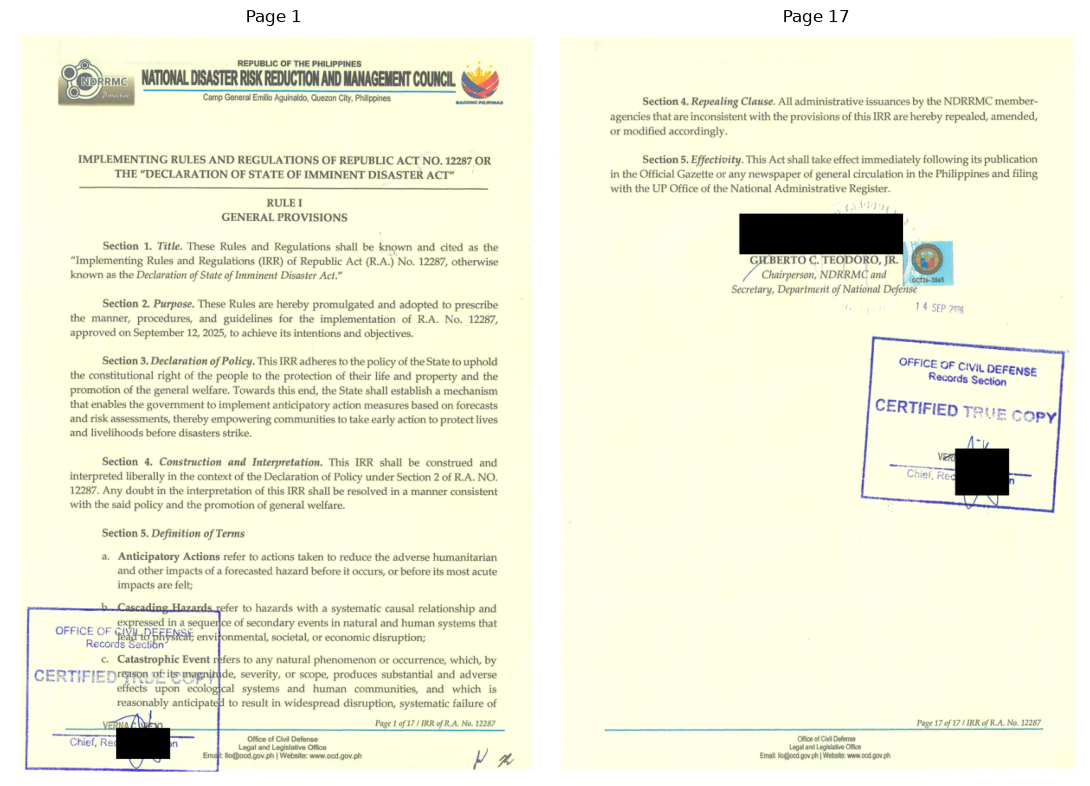

In [2]:
from pypdf import PdfReader

text_layer_chars = [len((page.extract_text() or "").strip()) for page in PdfReader(str(PDF_PATH)).pages]
print("Characters in the PDF's own text layer, per page:", text_layer_chars)

fig, axes = plt.subplots(1, 2, figsize=(11, 8))
for axis, page_number in zip(axes, (0, 16)):
    axis.imshow(ocr_tools.render_page(pdf, page_number, dpi=90))
    axis.set_title(f"Page {page_number + 1}")
    axis.axis("off")
plt.tight_layout()
plt.show()

## 2. Removing the stamp

The stamp is blue, the text is black. `remove_colour_ink` whitens every coloured pixel and flattens the yellow
paper to white, so the stamp no longer sits on top of the words. Look at the lower left of page 1 (where
sentences *b.* and *c.* are covered by the stamp), before and after.

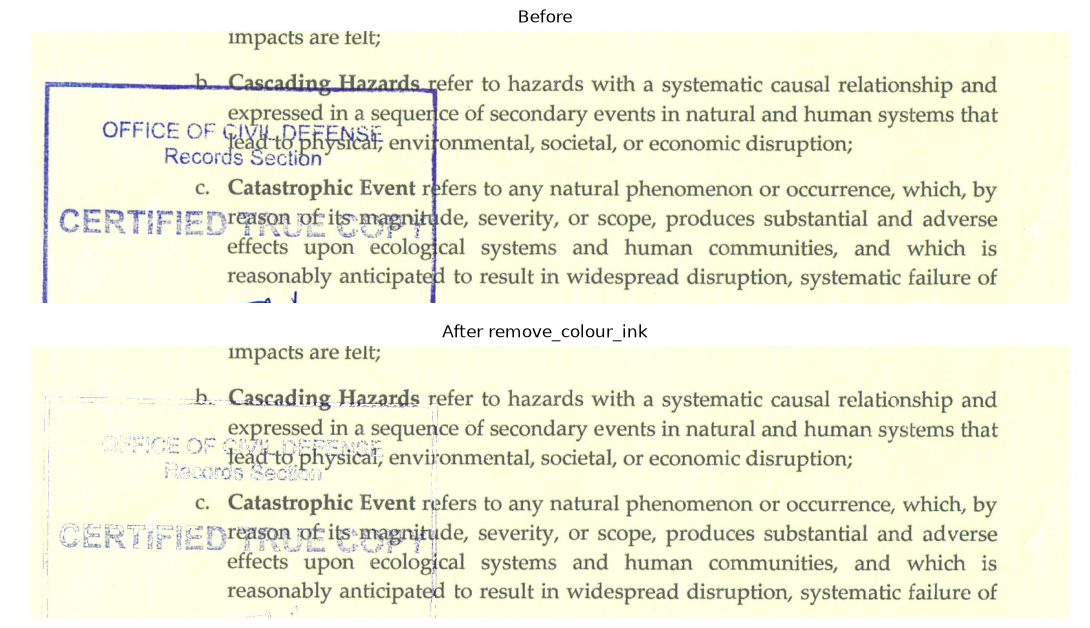

In [3]:
page_1 = ocr_tools.render_page(pdf, 0)
page_1_clean = ocr_tools.remove_colour_ink(page_1)

width, height = page_1.size
crop_box = (0, int(height * 0.74), width, int(height * 0.92))      # the part of the page the stamp covers
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5))
for axis, image, title in zip(axes, (page_1, page_1_clean), ("Before", "After remove_colour_ink")):
    axis.imshow(image.crop(crop_box))
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

## 3. Scoring the readers against text checked by hand

I typed out three pages from the images (`ocr_tools.REFERENCES`): **page 1** (the stamp covers sentences *b.* and *c.*),
**page 16** (the stamp covers Section 3) and **page 17** (the signature block). Each reader is scored on
**word error rate (WER)** and **character error rate (CER)**: the share of words or characters that must be changed,
added or removed to match the reference. Lower is better. Ligatures such as "ﬁ" are turned back into letters first.

| name | what |
|---|---|
| `tesseract_raw` | Tesseract on the original page: **what the pipeline used** |
| `tesseract_clean` | Tesseract on the page with the stamp removed |
| `got_bands_raw` | GOT-OCR-2.0 (an OCR model) on the original page, read in 3 bands |
| `combined` | the two above merged word by word (`ocr_tools.vote_readings`) |
| `got_raw`, `got_bands_clean` | tried and dropped: GOT-OCR on the whole page at once, and GOT-OCR on the stamp-free image |

GOT-OCR squeezes every image into a 1024 x 1024 square, so a whole A4 page is squashed and its text becomes tiny.
Reading in bands (padded to squares) fixes most of that. It is still not perfect: it sometimes drops a line or splits a word.
Tesseract is steadier but is confused by the stamp. The merge keeps the better of the two where they disagree.

dictionary for the merge and for the unknown-word check: 5,790 words from two other corpus PDFs


,page 1 WER,page 16 WER,page 17 WER,mean WER %,mean CER %
reader,,,,,
tesseract_raw,7.4,12.7,2.6,7.6,4.8
tesseract_clean,5.7,10.1,1.3,5.7,3.4
got_bands_raw,3.3,6.5,9.2,6.3,4.2
got_raw,3.9,10.1,96.1,36.7,35.2
got_bands_clean,10.7,9.2,15.8,11.9,4.5
combined,2.4,2.6,1.3,2.1,1.1


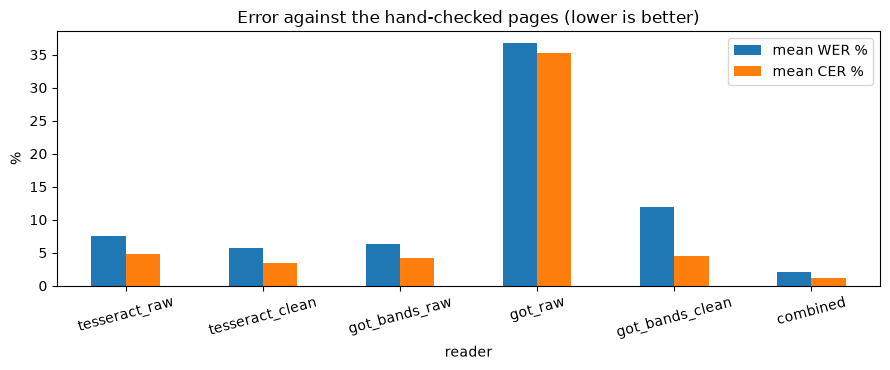

In [4]:
from src.rag.loaders import ocr_pdf_page

got = ocr_tools.GotOcr()
score_pages = sorted(ocr_tools.REFERENCES)           # [1, 16, 17]
page_image = lambda n: ocr_tools.render_page(pdf, n)

readers = {
    "tesseract_raw":    lambda n: ocr_pdf_page(PDF_PATH, n),
    "tesseract_clean":  lambda n: ocr_tools.tesseract_read(ocr_tools.remove_colour_ink(page_image(n))),
    "got_bands_raw":    lambda n: got.read_page(page_image(n)),
    "got_raw":          lambda n: got.read(page_image(n)),
    "got_bands_clean":  lambda n: got.read_page(ocr_tools.remove_colour_ink(page_image(n))),
}
vocabulary = ocr_tools.load_vocabulary()
print(f"dictionary for the merge and for the unknown-word check: {len(vocabulary):,} words from two other corpus PDFs")

readings = {name: {} for name in [*readers, "combined"]}
for page in score_pages:
    for name, read in readers.items():
        readings[name][page] = ocr_tools.cached_read(cache, name, page - 1, lambda: read(page - 1))
    readings["combined"][page] = ocr_tools.vote_readings(readings["tesseract_clean"][page], readings["got_bands_raw"][page], vocabulary)

rows = []
for name in readings:
    scores = [ocr_tools.score(page, readings[name][page]) for page in score_pages]
    rows.append({"reader": name,
                 **{f"page {p} WER": w for p, (w, _) in zip(score_pages, scores)},
                 "mean WER %": round(np.mean([w for w, _ in scores]), 1),
                 "mean CER %": round(np.mean([c for _, c in scores]), 1)})
results = pd.DataFrame(rows).set_index("reader")
display(results)

results[["mean WER %", "mean CER %"]].plot.bar(figsize=(9, 3.8), rot=15, title="Error against the hand-checked pages (lower is better)")
plt.ylabel("%")
plt.tight_layout()
plt.show()

**Where the errors are.** Section 3 of page 16 is printed under the stamp. The reference is compared with three readers:
`[-word-]` was in the reference but is missing, `{+word+}` was added by the reader.

In [5]:
def word_diff(reference, hypothesis, context=4):
    """Show a word-by-word difference: [-missing-] {+extra+}. Long stretches that agree are shortened to "…"."""
    pieces = []
    for opcode, a1, a2, b1, b2 in difflib.SequenceMatcher(a=reference, b=hypothesis, autojunk=False).get_opcodes():
        if opcode == "equal":
            same = reference[a1:a2]
            pieces.append(" ".join(same) if len(same) <= 2 * context else " ".join(same[:context]) + " … " + " ".join(same[-context:]))
        else:
            if a2 > a1:
                pieces.append("[-" + " ".join(reference[a1:a2]) + "-]")
            if b2 > b1:
                pieces.append("{+" + " ".join(hypothesis[b1:b2]) + "+}")
    return " ".join(pieces)


PAGE_TO_DIFF = 16
reference_words = ocr_tools.to_words(ocr_tools.REFERENCES[PAGE_TO_DIFF]["text"])
for name in ("tesseract_raw", "got_bands_raw", "combined"):
    hypothesis_words = ocr_tools.to_words(ocr_tools.compared_part(PAGE_TO_DIFF, readings[name][PAGE_TO_DIFF]))
    print(f"--- {name} (page {PAGE_TO_DIFF}):")
    print(word_diff(reference_words, hypothesis_words), "\n")

--- tesseract_raw (page 16):
rule vii capacity development … approval through the prescribed [-process-] {+pprocessvemuenenmrnenemurenen wae ecranilan thre vt+} section 3 separability clause if any [-provision of this irr-] {+p+} is [-declared-] {+r is+} unconstitutional by a tribunal of competent authority the [-remainder thereof not otherwise-] {+remaind r th r of het btherwise+} affected shall remain in full force and effect {+certified tot cay office of civil defense legal and legislative office email llo ocd gov ph website www ged gov ph atone+} 

--- got_bands_raw (page 16):
rule vii capacity development the [-ndrrmc-] {+ndrrm c+} shall develop and implement … issued prior to the [-effectivity-] {+effect iv it y+} of this [-irr-] {+i rr+} shall remain in force … the provisions of this [-irr-] {+i rr+} within a designated transition … which concerned agencies and [-lgus-] {+lg us+} shall undertake the necessary … section 2 review of [-the irr-] {+their r+} a review of the … of thi

## 4. All 17 pages: the old text against the new

The three hand-checked pages are not the whole document, so for every page two signs are used:

* **Unknown words**: the share of words (4+ letters) that never appear in two clean text-layer PDFs of the corpus
  (the flood plan and the preparedness manual). A reader that garbles words has more of them. Legal words that are
  simply rare count against every reader equally, so look at the *difference*.
* **Agreement**: how similar the two readers' texts are. A low value marks a page where they disagree: look at it.

In [6]:
for page_number in range(len(pdf)):
    for name in ("tesseract_raw", "tesseract_clean", "got_bands_raw"):
        ocr_tools.cached_read(cache, name, page_number, lambda: readers[name](page_number))
got.free()                                           # give the GPU memory back

pages = {name: [cache[f"{name}:{n}"] for n in range(len(pdf))] for name in ("tesseract_raw", "tesseract_clean", "got_bands_raw")}
pages["combined"] = [
    ocr_tools.vote_readings(a, b, vocabulary) for a, b in zip(pages["tesseract_clean"], pages["got_bands_raw"])
]
final_pages = pages["combined"]
print("pages read:", {name: len(texts) for name, texts in pages.items()})

pages read: {'tesseract_raw': 17, 'tesseract_clean': 17, 'got_bands_raw': 17, 'combined': 17}


,unknown % old (tesseract_raw),unknown % new (combined),agreement % (tesseract vs got),words old,words new,got looped?
page,,,,,,
1,20.6,16.6,91.1,391,390,
2,12.9,11.1,96.4,426,416,
3,16.7,14.4,77.5,387,383,
4,10.3,9.7,87.9,377,371,
5,8.0,6.2,90.2,460,455,
6,14.7,11.9,93.7,348,346,
7,11.7,10.9,82.6,360,305,
8,13.7,9.8,93.5,316,310,
9,15.6,15.2,18.2,343,335,YES


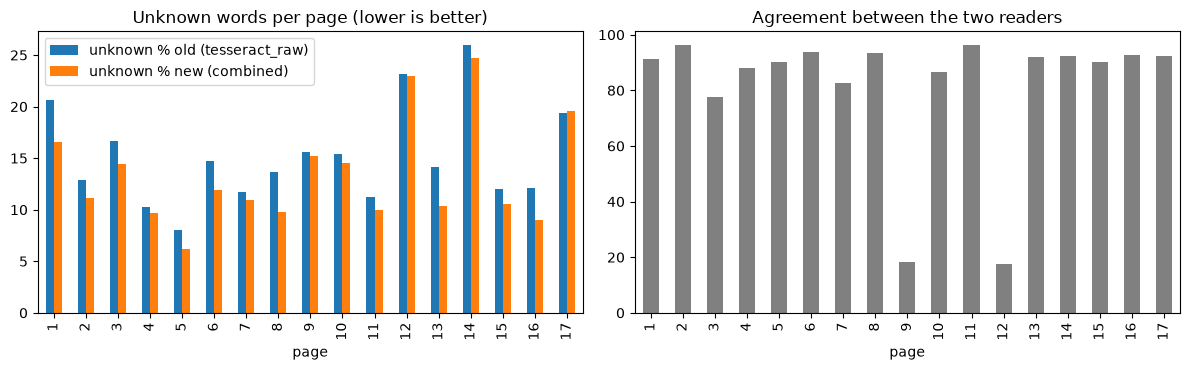

mean unknown-word %  old: 15.15  new: 13.39


In [7]:
to_words = ocr_tools.to_words


def unknown_word_rate(text):
    words = [word for word in to_words(text) if len(word) >= 4 and word.isalpha()]
    return 100 * sum(word not in vocabulary for word in words) / max(len(words), 1)


def agreement(text_a, text_b):
    return 100 * difflib.SequenceMatcher(a=to_words(text_a), b=to_words(text_b), autojunk=False).ratio()


per_page = pd.DataFrame({
    "page": range(1, len(pdf) + 1),
    "unknown % old (tesseract_raw)": [unknown_word_rate(t) for t in pages["tesseract_raw"]],
    "unknown % new (combined)":      [unknown_word_rate(t) for t in final_pages],
    "agreement % (tesseract vs got)": [agreement(a, b) for a, b in zip(pages["tesseract_clean"], pages["got_bands_raw"])],
    "words old": [len(to_words(t)) for t in pages["tesseract_raw"]],
    "words new": [len(to_words(t)) for t in final_pages],
    # GOT-OCR repeating itself (far more words than Tesseract): its text is ignored for that page.
    "got looped?": ["YES" if ocr_tools.looks_like_a_loop(a, b) else "" for a, b in zip(pages["tesseract_clean"], pages["got_bands_raw"])],
}).set_index("page")
per_page = per_page.round({column: 1 for column in per_page.columns if column != "got looped?"})
display(per_page)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
per_page[["unknown % old (tesseract_raw)", "unknown % new (combined)"]].plot.bar(ax=axes[0], title="Unknown words per page (lower is better)")
per_page["agreement % (tesseract vs got)"].plot.bar(ax=axes[1], color="grey", title="Agreement between the two readers")
plt.tight_layout()
plt.show()
print("mean unknown-word %  old:", per_page.iloc[:, 0].mean().round(2), " new:", per_page.iloc[:, 1].mean().round(2))

**Inspect a page.** Change `PAGE_TO_INSPECT` to look at any page: the scan, then the old text, the GOT-OCR text and the
combined text side by side.

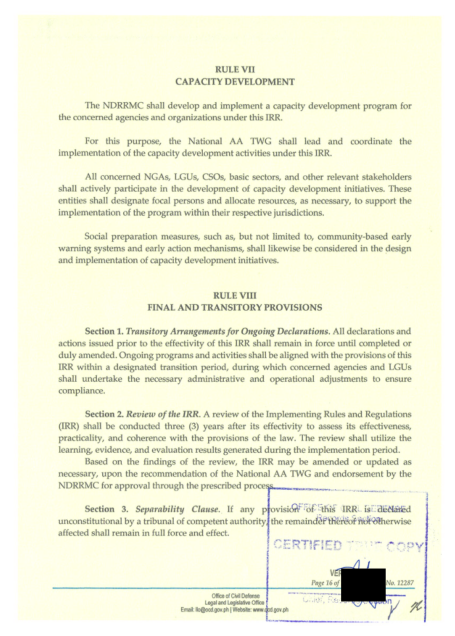

In [8]:
PAGE_TO_INSPECT = 16                                 # 1 to 17

index = PAGE_TO_INSPECT - 1
plt.figure(figsize=(6, 8))
plt.imshow(ocr_tools.render_page(pdf, index, dpi=80))
plt.axis("off")
plt.show()

def column(title, text):
    safe = text.replace("&", "&amp;").replace("<", "&lt;")
    return f"<div style='flex:1;margin:4px;min-width:0'><b>{title}</b><pre style='white-space:pre-wrap;font-size:11px'>{safe}</pre></div>"

display(HTML("<div style='display:flex'>"
             + column("Old: Tesseract on the original", pages["tesseract_raw"][index])
             + column("GOT-OCR in bands", pages["got_bands_raw"][index])
             + column("Combined (new)", final_pages[index])
             + "</div>"))

## 5. Cleaning the text

Every page ends with a footer ("Page 3 of 17 / IRR of R.A. No. 12287", then the Office of Civil Defense address and
e-mail) and the stamp leaves a few words behind ("CERTIFIED TRUE COPY", the certifier's name). These words would be
in every chunk and match every question a little, so they are removed. Everything from the "Page N" footer to the end
of the page is boilerplate (and the OCR junk after it), so it is cut off; the remaining stamp words are removed by
pattern. A real mention of the office in the text ("The Office of Civil Defense (OCD) shall monitor...") is kept.
The table shows **exactly what was removed**.

Then the text is given structure: a paragraph break before each "Section N." and each "RULE" becomes a
Markdown heading (`# RULE I - GENERAL PROVISIONS`), which the project's chunker turns into a heading path
that is added to the chunk.

In [9]:
# (name, pattern). Applied to text whose whitespace has been collapsed to single spaces; readers add stray spaces
# inside e-mail addresses, so the patterns allow them.
BOILERPLATE = [
    # (name, pattern, case-sensitive?). The readers misspell the stamp ("DEEENSE") and add stray spaces and bars, so the
    # patterns are loose. The stamp is in capitals; "Office of Civil Defense" in the body text is a real mention of the
    # office and must stay, so it is removed only together with "Legal and Legislative Office".
    ("page footer",     r"(?:Page\s*)?\d+\s*of\s*17\s*/?\s*I\s*R\s*R\s*of\.?\s*R\.\s*A\.\s*No\.\s*12287", False),
    ("website",         r"\|?\s*Website:?\s*(?:www\.?\s*)?\w+\.\s*gov\.\s*ph", False),
    ("e-mail",          r"\b[BE]\s*mai\s*l?:?\s*l?\s*lo\s*@\s*\w+\.\s*gov\.\s*ph\s*\|?", False),
    ("office address",  r"(?:Office\s+of\s+Civil\s+D\w{2,6}\s*)?Legal\s+and\s+Legislative\s+Office", False),
    ("stamp (capitals)", r"OFFICE\s+OF\s+CIVIL\s+DE\w{2,6}", True),
    ("stamp text",      r"Records?\s+Section|CERT\w{2,8}\s+TRUE\s+COPY|\bCERTIFIED\b|Chief,?\s+Rec\w*", False),
    ("certifier name",  r"\bVERN\w*\s+(?:A\s+)?(?:C\.?\s+)?(?:VIEJO|RACE\s+IN)\b", False),
]


FOOTER_WINDOW_WORDS = 45                              # the footer is within the last 45 words of a page


def clean_page(text, page_number):
    """Collapse whitespace and cut the boilerplate. Returns (clean text, [(page, name, removed text), ...])."""
    text = re.sub(r"\s+", " ", text).strip()
    removed = []

    # 1. The page footer starts with "Page N of 17"; it and everything after it (address, e-mail, junk) goes.
    words = text.split()
    for index in range(len(words) - 1, max(len(words) - FOOTER_WINDOW_WORDS, 0) - 1, -1):
        if re.fullmatch(r"page\W*", words[index], flags=re.I):
            removed.append((page_number, "footer: from 'Page N' to the end", " ".join(words[index:])))
            text = " ".join(words[:index])
            break
    text = re.sub(r"(?<!\S)[|_~\\]+(?!\S)", " ", text)       # stray symbols left by the stamp edges

    # 2. What is left of the letterhead and stamp inside the page.
    for name, pattern, case_sensitive in BOILERPLATE:
        flags = 0 if case_sensitive else re.I
        for match in re.finditer(pattern, text, flags=flags):
            removed.append((page_number, name, match.group(0)))
        text = re.sub(pattern, " ", text, flags=flags)
    return re.sub(r"\s+", " ", text).strip(), removed


cleaned_pages, removed_rows = [], []
for number, text in enumerate(final_pages, start=1):
    page_text, removed = clean_page(text, number)
    cleaned_pages.append(page_text)
    removed_rows += removed

removed_table = pd.DataFrame(removed_rows, columns=["page", "what", "text"])
display(removed_table.groupby("what").agg(times=("text", "size"), examples=("text", lambda s: " | ".join(sorted(set(s))[:3]))))
print("words before / after cleaning:", sum(len(t.split()) for t in final_pages), "/", sum(len(t.split()) for t in cleaned_pages))

,times,examples
what,,
e-mail,1,Email: llo@ocd.gov.ph
footer: from 'Page N' to the end,15,Page 1 002 1 Office of Civil Defense * = LATE ...
office address,1,Legal and Legislative Office
stamp (capitals),3,OFFICE OF CIVIL DEEENSE | OFFICE OF CIVIL DEFENSE
stamp text,6,CERTIFIED | RECORDS Section | Records Section


words before / after cleaning: 5916 / 5455


In [10]:
ROMAN_NUMERALS = ["I", "II", "III", "IV", "V", "VI", "VII", "VIII", "IX", "X"]
PAGE_MARK = re.compile(r"§§PAGE\d+§§")                # marks where a page starts; removed again before chunking


def add_structure(text, headings=True):
    """Paragraph break before "Section N." and a title line for each "RULE <number> <TITLE>".

    With ``headings=True`` the title is a Markdown heading ("# RULE I - GENERAL PROVISIONS"), which the project's chunker
    cuts sections at and adds to every chunk as a heading path. With ``headings=False`` it is an ordinary line of text.

    The whole document is structured at once, because a title can run across a page break. The rules come in order and
    the readers misread their numbers (II read as "I", III as "Il ~"), so each title is numbered by its position.
    The page markers stay where they were (a marker inside a title is moved to just after it).
    """
    count = [0]
    mark = r"(?:§§PAGE\d+§§\s+)?"                          # an optional page marker between words
    prefix = "# " if headings else ""

    def title_line(match):
        count[0] += 1
        markers = PAGE_MARK.findall(match.group(1))
        title = PAGE_MARK.sub("", match.group(1)).strip()
        return f"\n\n{prefix}RULE {ROMAN_NUMERALS[count[0] - 1]} - {title}\n\n" + "".join(marker + " " for marker in markers)

    # RULE I GENERAL PROVISIONS  ->  RULE I - GENERAL PROVISIONS   (the title is the capital words that follow,
    # up to the first word with a lowercase letter)
    text = re.sub(
        rf"\bRULE\s+[IVXLl1|]+\s*[~-]?\s+((?:{mark}[A-Z][A-Z,&'-]*\s+)+?)(?={mark}\S*[a-z])", title_line, text
    )
    return re.sub(r"(?<!\n)\s+(?=Section\s+\d+\.\s)", "\n\n", text)


# Two layouts of the same text, compared in sections 6 and 7.
marked_text = " ".join(f"§§PAGE{number}§§ {page_text}" for number, page_text in enumerate(cleaned_pages, start=1))
marked_structured = {"headings": add_structure(marked_text, headings=True), "plain": add_structure(marked_text, headings=False)}

found = re.findall(r"^# .*$", PAGE_MARK.sub("", marked_structured["headings"]), flags=re.M)
print(len(found), "rule titles found (the IRR has 8 rules):")
print("\n".join(found))

8 rule titles found (the IRR has 8 rules):
# RULE I - GENERAL PROVISIONS
# RULE II - CRITERIA FOR DECLARATION AND LIFTING OF A STATE OF IMMINENT DISASTER
# RULE III - AUTHORITY TO DECLARE AND LIFT A STATE OF IMMINENT DISASTER
# RULE IV - ANTICIPATORY ACTION MEASURES
# RULE V - FUNDING AND BUDGETING
# RULE VI - MONITORING, REPORTING, AND EVALUATION
# RULE VII - CAPACITY DEVELOPMENT
# RULE VIII - FINAL AND TRANSITORY PROVISIONS


## 6. Metadata, chunks and page numbers

The document is chunked by the project's own `chunk_document` (the same code the pipeline uses: pieces of at most 400
words with 50 words repeated between neighbours). Every chunk gets the metadata above, the **page it starts on**
(`page`) and the page it ends on (`page_end`). The page is found by locating the first words of each chunk in the
page-by-page text.

Two layouts of the same cleaned text are built, to find out which one the search likes better:

* **`headings`**: each rule title is a Markdown heading. The chunker cuts at it and prints it above every chunk of that rule.
* **`plain`**: the rule title stays an ordinary line of text. Chunks are cut only by size.

In [11]:
from src.rag.chunking import chunk_document
from src.rag.models import Document


def build_chunks(layout):
    """Chunk one layout and give every chunk its page and page_end."""
    marked = marked_structured[layout]

    # One list of words with the page each word belongs to, so a chunk's words can be traced back to a page.
    word_list, word_page, current_page = [], [], 1
    for token in marked.split():                     # the page markers say where each page starts
        if PAGE_MARK.fullmatch(token):
            current_page = int(re.findall(r"\d+", token)[0])
        else:
            word_list.append(token)
            word_page.append(current_page)

    def page_range(chunk_body, search_from):
        """(first page, last page, where the chunk starts), found by matching the first 8 words of the chunk."""
        body_words = chunk_body.split()
        head = body_words[:8]
        for start in range(search_from, len(word_list) - len(head) + 1):
            if word_list[start : start + len(head)] == head:
                end = start + len(body_words) - 1
                return word_page[start], word_page[min(end, len(word_page) - 1)], start
        return None, None, search_from

    document = Document(doc_id=DOC_ID, text=PAGE_MARK.sub("", marked), doc_type="manual", metadata=dict(DOC_METADATA))
    chunks, search_from = chunk_document(document), 0
    for chunk in chunks:
        body = chunk.content.splitlines()[-1]        # a chunk is: header line, heading path (if any), body
        first_page, last_page, found_at = page_range(body, search_from)
        chunk.metadata["page"], chunk.metadata["page_end"] = first_page, last_page
        search_from = max(found_at, search_from)     # chunks come in order, so the next one starts later
    return chunks


layouts = {name: build_chunks(name) for name in marked_structured}
display(pd.DataFrame({
    name: {
        "chunks": len(chunks),
        "words per chunk (average)": round(np.mean([len(c.content.split()) for c in chunks])),
        "smallest chunk (words)": min(len(c.content.split()) for c in chunks),
        "chunks with no page found": sum(c.metadata["page"] is None for c in chunks),
    }
    for name, chunks in layouts.items()
}))

,headings,plain
chunks,21,20
words per chunk (average),298,326
smallest chunk (words),45,109
chunks with no page found,0,0


**Which layout is written?** Set `LAYOUT` below. The choice was made from the search results in section 7: with the full
search, `plain` found the right passage more often than `headings` (the rule titles repeated in every chunk made the
chunks of one rule look alike, and the short first chunks full of "IRR" and "RA 12287" outranked the real answers).
Change it and run again to try the other one.

In [12]:
LAYOUT = "plain"                                      # "headings" or "plain": "plain" did better in section 7

new_chunks = layouts[LAYOUT]
chunk_table = pd.DataFrame({
    "chunk": [c.chunk_idx for c in new_chunks],
    "page": [c.metadata["page"] for c in new_chunks],
    "page_end": [c.metadata["page_end"] for c in new_chunks],
    "words": [len(c.content.split()) for c in new_chunks],
    "starts with": [c.content.replace("\n", " | ")[:110] for c in new_chunks],
}).set_index("chunk")
pd.set_option("display.max_colwidth", 120)
display(chunk_table)
print(f"layout '{LAYOUT}':", len(new_chunks), "chunks")
print("pages without a chunk starting on them:", sorted(set(range(1, 18)) - set(chunk_table["page"].dropna().astype(int))))
print("chunks with no page found:", int(chunk_table["page"].isna().sum()))

,page,page_end,words,starts with
chunk,,,,
0,1,1,251,[NDRRMC | manual | 2026-09-14] | REPUBLIC OF THE PHILIPPINES NATIONAL DISASTER RISK REDUCTION AND MANAGEMENT C
1,1,2,405,[NDRRMC | manual | 2026-09-14] | and Interpretation. This IRR shall be construed and interpreted liberally in
2,2,3,302,"[NDRRMC | manual | 2026-09-14] | occurrence of a predicted event. The time span can range from hours to days,"
3,3,4,324,"[NDRRMC | manual | 2026-09-14] | 12287, with projected catastrophic impacts that are categorized as “severe,”"
4,3,4,323,"[NDRRMC | manual | 2026-09-14] | NO. 12287 and this my shall be immediately implemented, provided, that the sa"
5,4,5,332,[NDRRMC | manual | 2026-09-14] | government agencies and LGUs shall shift to regular response and early recove
6,5,6,270,"[NDRRMC | manual | 2026-09-14] | the RDRRMC receives a request from the Provincial, City, or Municipal DRRMC t"
7,5,7,405,"[NDRRMC | manual | 2026-09-14] | Rule ti, Gection.6,of this IRR, the following shall have the authority to lif"
8,7,8,368,"[NDRRMC | manual | 2026-09-14] | the most vulnerable communities, even when a forecasted hazard does not mater"


layout 'plain': 20 chunks
pages without a chunk starting on them: [6, 17]
chunks with no page found: 0


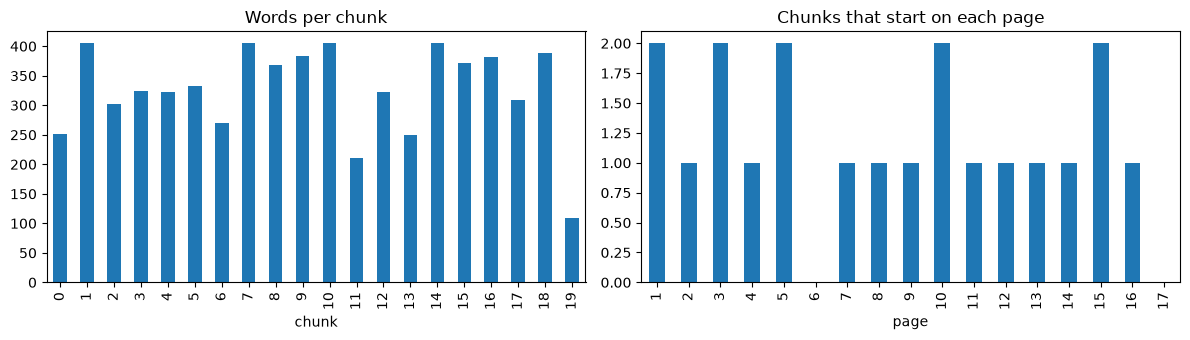

Metadata of the first chunk:
{
  "source": "20260914-NDRRMC-IRR-RA12287.pdf",
  "title": "Implementing Rules and Regulations of Republic Act No. 12287 (Declaration of State of Imminent Disaster Act)",
  "agency": "NDRRMC",
  "trust_tier": "official",
  "issued_at": "2026-09-14",
  "hazard": null,
  "language": "en",
  "ocr_engine": "Tesseract (stamp removed) + GOT-OCR-2.0, merged",
  "doc_type": "manual",
  "page": 1,
  "page_end": 1
}

What a chunk looks like when the answer agent sees it (see format_sources in document_agents.py):
[NDRRMC | manual | 2026-09-14]
12287, with projected catastrophic impacts that are categorized as “severe,” or its equivalent, based on forecast and the results of a pre- disaster risk assessment. Health hazards arising from or exacerbated by hydrometeorological, geological, and climatic hazards shall be included within the scope of anticipatory action measures of this IRR. Section 2. Triggers and Thresholds. The State of Imminent Disaster may be declared w

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
chunk_table["words"].plot.bar(ax=axes[0], title="Words per chunk")
chunk_table.groupby("page").size().reindex(range(1, 18), fill_value=0).plot.bar(ax=axes[1], title="Chunks that start on each page")
plt.tight_layout()
plt.show()

print("Metadata of the first chunk:")
print(json.dumps(new_chunks[0].metadata, indent=2, ensure_ascii=False))
print()
print("What a chunk looks like when the answer agent sees it (see format_sources in document_agents.py):")
print(new_chunks[3].content[:700])

## 7. Old chunks vs new chunks: the same questions

The old chunks are read from Supabase (the notebook keeps a copy in `_cache/old_chunks_backup.json`, made before any
change). Each question is turned into a vector with the project's embedding model (`multilingual-e5-large`) and
ranked against every chunk of each version, the way the answer agent searches (the agent also uses keyword search and
a re-ranker; only the vector search is tested here).

Similarity scores of different texts are not comparable, so each question comes with a **phrase that the right
passage must contain** (taken from the page images; both the old and the new text contain every phrase, so a
difference comes from how the text is cut and labelled, not from misread words). The table shows where the first chunk
containing that phrase ranks: **1 means the search put the right passage first**.

In [14]:
from src.rag import embeddings
from src.services.fetch_postgre_database import get_connection

with get_connection() as conn:
    old_rows = conn.execute(
        "SELECT chunk_idx, content, metadata, embedding::text AS embedding FROM chunks WHERE doc_id = %s ORDER BY chunk_idx",
        (DOC_ID,),
    ).fetchall()
backup_file = CACHE_DIR / "old_chunks_backup.json"
if not backup_file.exists():                         # keep the very first copy: it is the state before any re-ingestion
    backup_file.write_text(json.dumps(old_rows, ensure_ascii=False, default=str))
old_chunks = json.loads(backup_file.read_text())
old_vectors = np.array([json.loads(row["embedding"]) for row in old_chunks])

versions = {"old": ([row["content"] for row in old_chunks], old_vectors)}
for name, chunks in layouts.items():
    texts = [chunk.content for chunk in chunks]
    versions[name] = (texts, np.array(embeddings.embed_texts(texts)))
new_vectors = versions[LAYOUT][1]
for name, (texts, _) in versions.items():
    print(f"{name:9s} {len(texts):3d} chunks, {sum(len(t.split()) for t in texts):6,} words")

/home/kenneth28/my_projects/Flood-Gentic/backend/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   1%|▏         | 5/391 [00:00<00:21, 18.07it/s]

Loading weights:   2%|▏         | 7/391 [00:00<00:23, 16.47it/s]

Loading weights:   2%|▏         | 9/391 [00:00<00:41,  9.10it/s]

Loading weights:   3%|▎         | 11/391 [00:01<00:50,  7.57it/s]

... (19 outputs left out)

Loading weights:  67%|██████▋   | 262/391 [00:06<00:00, 137.46it/s]

Loading weights:  72%|███████▏  | 280/391 [00:06<00:01, 66.04it/s] 

Loading weights: 100%|██████████| 391/391 [00:07<00:00, 55.65it/s]

old        18 chunks,  6,782 words
headings   21 chunks,  6,253 words
plain      20 chunks,  6,513 words


,old,headings,plain
What is a State of Imminent Disaster?,2,8,5
Ano ang ibig sabihin ng lead time?,1,7,10
When will the IRR be reviewed and amended?,1,1,1
What are the essential relief commodities?,1,3,2
Who chairs the NDRRMC and signed the IRR?,1,3,1
What happens to declarations issued before the IRR takes effect?,1,2,5
What are cascading hazards?,17,1,1
What is a pre-disaster risk assessment?,1,1,1
What counts as critical infrastructure?,1,1,2
What are anticipatory actions?,4,10,10


,old,headings,plain
"1st, all (of 21)",15,9,8
"top 3, all (of 21)",17,15,14
"1st, naming the IRR (of 7)",4,2,1
"top 3, naming the IRR (of 7)",5,4,4
"1st, not naming it (of 14)",11,7,7
"top 3, not naming it (of 14)",12,11,10


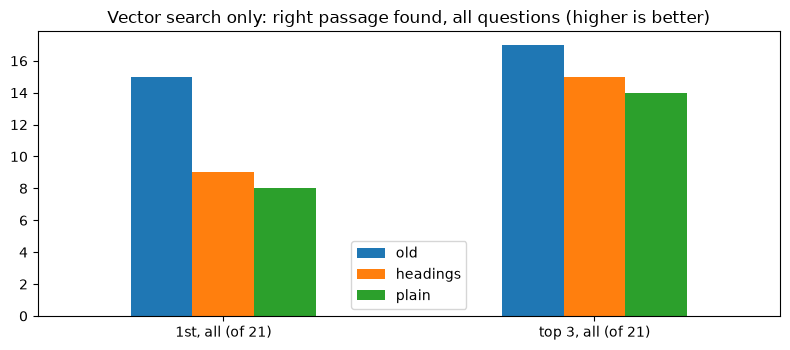

In [15]:
# (question, a phrase the right passage must contain)
QUESTIONS = [
    ("What is a State of Imminent Disaster?",                            "highly probable disaster"),
    ("Ano ang ibig sabihin ng lead time?",                               "period between the issuance of a forecast"),
    ("When will the IRR be reviewed and amended?",                       "three (3) years after its effectivity"),
    ("What are the essential relief commodities?",                       "relief commodities"),
    ("Who chairs the NDRRMC and signed the IRR?",                        "teodoro"),
    ("What happens to declarations issued before the IRR takes effect?", "remain in force until completed"),
    ("What are cascading hazards?",                                      "systematic causal relationship"),
    ("What is a pre-disaster risk assessment?",                          "process of evaluating a hazard's level of risk"),
    ("What counts as critical infrastructure?",                          "physical structures, facilities, networks"),
    ("What are anticipatory actions?",                                   "actions taken to reduce the adverse humanitarian"),
    ("What if part of the IRR is declared unconstitutional?",            "unconstitutional by a tribunal of competent authority"),
    ("When does the IRR take effect?",                                   "publication in the official gazette"),
    ("Which office monitors the areas under a declaration?",             "shall monitor the areas declared"),
    ("Ano ang programa para sa capacity development?",                   "capacity development program for the concerned agencies"),
    # The same kind of question, but naming the law the way people do. These chunks must beat the title chunk, which repeats "IRR" and "RA 12287".
    ("When will the IRR of RA 12287 be reviewed and amended?",           "three (3) years after its effectivity"),
    ("What is the lead time under the IRR of RA 12287?",                 "period between the issuance of a forecast"),
    ("Who signed the IRR of RA 12287?",                                  "teodoro"),
    ("What does the IRR of RA 12287 say about cascading hazards?",       "systematic causal relationship"),
    ("What are the anticipatory actions in the IRR of RA 12287?",        "actions taken to reduce the adverse humanitarian"),
    ("When does the IRR of RA 12287 take effect?",                       "publication in the official gazette"),
    ("Ano ang sinasabi ng IRR ng RA 12287 tungkol sa capacity development?", "capacity development program for the concerned agencies"),
]
NAMES_THE_LAW = ["12287" in question for question, _ in QUESTIONS]
question_vectors = np.array(embeddings.embed_texts([q for q, _ in QUESTIONS], is_query=True))


def contains(text, phrase):
    """True when the phrase's words appear one after the other in the text (case, punctuation and ligatures ignored)."""
    return " ".join(ocr_tools.to_words(phrase)) in " ".join(ocr_tools.to_words(text))


def rank_of_right_passage(vector, vectors, texts, phrase):
    """1-based rank of the best-ranked chunk that contains the phrase, or None."""
    for rank, index in enumerate(np.argsort(-(vectors @ vector)), start=1):   # vectors are normalised: dot product = cosine
        if contains(texts[index], phrase):
            return rank
    return None


ranks = pd.DataFrame(
    {
        name: [rank_of_right_passage(vector, vectors, texts, phrase) or 99 for (_, phrase), vector in zip(QUESTIONS, question_vectors)]
        for name, (texts, vectors) in versions.items()
    },
    index=[question for question, _ in QUESTIONS],
)
display(ranks.replace(99, "not found"))

def summarise(rank_table):
    """Count the questions where the right passage came first / in the top 3, for all questions and for those naming the law."""
    named = np.array(NAMES_THE_LAW)
    rows = {}
    for label, mask in (("all", np.ones(len(named), bool)), ("naming the IRR", named), ("not naming it", ~named)):
        rows[f"1st, {label} (of {int(mask.sum())})"] = {name: int((rank_table[name][mask] == 1).sum()) for name in rank_table}
        rows[f"top 3, {label} (of {int(mask.sum())})"] = {name: int((rank_table[name][mask] <= 3).sum()) for name in rank_table}
    return pd.DataFrame(rows).T


summary = summarise(ranks)
display(summary)
summary.iloc[:2].plot.bar(figsize=(8, 3.6), rot=0, title="Vector search only: right passage found, all questions (higher is better)")
plt.tight_layout()
plt.show()

### The full search

The answer agent does not use vector search alone: it also runs a keyword search (BM25), merges the two result lists
(`reciprocal_rank_fusion`) and lets a re-ranking model (`BAAI/bge-reranker-v2-m3`) put the best passages first. The same
steps are run here, with the project's own code, on each version of this one document.

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:  34%|███▍      | 135/393 [00:00<00:00, 1335.97it/s]

Loading weights:  68%|██████▊   | 269/393 [00:00<00:00, 1206.09it/s]

Loading weights: 100%|██████████| 393/393 [00:00<00:00, 1337.73it/s]

,old,headings,plain
What is a State of Imminent Disaster?,1,3,3
Ano ang ibig sabihin ng lead time?,1,1,1
When will the IRR be reviewed and amended?,1,1,1
What are the essential relief commodities?,1,1,1
Who chairs the NDRRMC and signed the IRR?,1,1,1
What happens to declarations issued before the IRR takes effect?,1,1,1
What are cascading hazards?,6,1,1
What is a pre-disaster risk assessment?,1,1,1
What counts as critical infrastructure?,1,1,1
What are anticipatory actions?,1,1,1


,old,headings,plain
"1st, all (of 21)",18,15,17
"top 3, all (of 21)",19,18,19
"1st, naming the IRR (of 7)",5,2,4
"top 3, naming the IRR (of 7)",6,4,5
"1st, not naming it (of 14)",13,13,13
"top 3, not naming it (of 14)",13,14,14


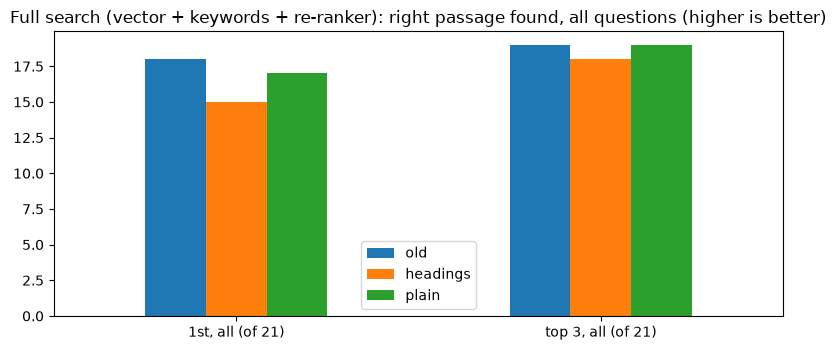

In [16]:
from src.rag.bm25 import BM25Index
from src.rag.fusion import bm25_weight_for, reciprocal_rank_fusion
from src.rag.models import Chunk
from src.rag.reranking import rerank

version_chunks = {"old": [Chunk(DOC_ID, row["chunk_idx"], row["content"], row["metadata"]) for row in old_chunks], **layouts}
bm25_indexes = {name: BM25Index(chunks) for name, chunks in version_chunks.items()}
CANDIDATES_PER_SEARCH = 30


def full_search_rank(name, question, question_vector, phrase):
    """1-based rank of the first chunk containing the phrase after vector search + BM25 + fusion + re-ranking (99 = not found)."""
    chunks, vectors = version_chunks[name], versions[name][1]
    best = np.argsort(-(vectors @ question_vector))[:CANDIDATES_PER_SEARCH]
    fused = reciprocal_rank_fusion(
        [[chunks[i] for i in best], bm25_indexes[name].search(question, CANDIDATES_PER_SEARCH)],
        weights=[1.0, bm25_weight_for(question)],
        top_n=40,
    )
    for rank, chunk in enumerate(rerank(question, fused, top_n=len(fused)), start=1):
        if contains(chunk.content, phrase):
            return rank
    return 99


full_ranks = pd.DataFrame(
    {
        name: [full_search_rank(name, question, vector, phrase) for (question, phrase), vector in zip(QUESTIONS, question_vectors)]
        for name in version_chunks
    },
    index=[question for question, _ in QUESTIONS],
)
display(full_ranks.replace(99, "not found"))

full_summary = summarise(full_ranks)
display(full_summary)
full_summary.iloc[:2].plot.bar(figsize=(8, 3.6), rot=0, title="Full search (vector + keywords + re-ranker): right passage found, all questions (higher is better)")
plt.tight_layout()
plt.show()

**Read the best match.** This shows the passage each version would hand to the answer model for one question
(change `SHOW`), so you can check with your own eyes that it answers the question.

In [17]:
SHOW = 4                                             # index into QUESTIONS
vector = question_vectors[SHOW]
best_old, best_new = int((old_vectors @ vector).argmax()), int((new_vectors @ vector).argmax())
print("QUESTION:", QUESTIONS[SHOW][0], "\n")
print("OLD best chunk:\n", old_chunks[best_old]["content"][:900], "\n")
print(f"NEW best chunk (page {new_chunks[best_new].metadata['page']}):\n", new_chunks[best_new].content[:900])

QUESTION: Who chairs the NDRRMC and signed the IRR? 

OLD best chunk:
 [manual]
to the effectivity of this IRR shall remain in force until completed or duly amended. Ongoing programs and activities shall be aligned with the provisions of this IRR within a designated transition period, during which concerned agencies and LGUs shall undertake the necessary administrative and operational adjustments to ensure compliance. Section 2. Review of the IRR. A review of the Implementing Rules and Regulations (IRR) shall be conducted three (3) years after its effectivity to assess its effectiveness, practicality, and coherence with the provisions of the law. The review shall utilize the learning, evidence, and evaluation results generated during the implementation period. Based on the findings of the review, the IRR may be amended or updated as necessary, upon the recommendation of the National AA TWG and endorsement by the NDRRMC for approval through the prescribed Pp 

NEW best chunk (page 16):


## 8. Writing the new chunks

Runs only with `REINGEST_WRITE=1`. In one transaction the document's old chunks are deleted and the new ones
inserted (a plain re-ingest would leave old chunks behind when the document gets shorter). Then a **new FAISS run**
is saved: the latest run with this document swapped for the new chunks. That matters because
`scripts/load_to_supabase.py` copies the latest FAISS run into Supabase and would otherwise bring the old chunks back.

In [18]:
from src.rag import faiss_store, vector_store
from src.rag.models import Chunk

if not WRITE:
    print("Writes are OFF. Nothing was changed in Supabase or faiss_vectors/. Run with REINGEST_WRITE=1 to write.")
else:
    hashes = [vector_store.content_hash(chunk.content) for chunk in new_chunks]
    with get_connection() as conn:
        vector_store.ensure_schema(conn)
        with conn.transaction():                     # both steps or neither
            deleted = conn.execute("DELETE FROM chunks WHERE doc_id = %s", (DOC_ID,)).rowcount
            vector_store.upsert_chunks(conn, new_chunks, new_vectors.tolist(), hashes)
        stored = conn.execute("SELECT count(*) AS n FROM chunks WHERE doc_id = %s", (DOC_ID,)).fetchone()["n"]
    print(f"Supabase: deleted {deleted} old chunks, wrote {len(new_chunks)}; table now holds {stored} for this document.")

    # A new FAISS run: every other document keeps its saved vectors; this one gets the new chunks.
    latest_run = sorted(path for path in FAISS_DIR.iterdir() if path.is_dir())[-1]
    index, records, run_info = faiss_store.load_run(latest_run)
    saved_vectors = index.reconstruct_n(0, index.ntotal)
    keep = [i for i, record in enumerate(records) if record["doc_id"] != DOC_ID]
    kept_chunks = [Chunk(records[i]["doc_id"], records[i]["chunk_idx"], records[i]["content"], records[i]["metadata"]) for i in keep]
    run_dir = faiss_store.save_run(
        FAISS_DIR,
        kept_chunks + new_chunks,
        saved_vectors[keep].tolist() + new_vectors.tolist(),
        run_info["embedding_model"],
        sorted(path for path in (REPO_DIR / "corpus").iterdir() if path.suffix.lower() in {".pdf", ".csv"}),
    )
    print(f"FAISS: {latest_run.name} ({len(records)} chunks) -> {run_dir.name} ({len(kept_chunks) + len(new_chunks)} chunks)")

Supabase: deleted 21 old chunks, wrote 20; table now holds 20 for this document.


FAISS: 20261101-115513_multilingual-e5-large (464 chunks) -> 20261101-122238_multilingual-e5-large (463 chunks)


## 9. Check what is stored

In [19]:
with get_connection() as conn:
    stored = conn.execute(
        """SELECT chunk_idx, metadata->>'page' AS page, metadata->>'agency' AS agency, metadata->>'trust_tier' AS trust,
                  metadata->>'issued_at' AS issued, length(content) AS characters, embedding IS NOT NULL AS has_vector
           FROM chunks WHERE doc_id = %s ORDER BY chunk_idx""",
        (DOC_ID,),
    ).fetchall()
display(pd.DataFrame(stored).set_index("chunk_idx"))
print(f"{len(stored)} chunks stored in Supabase for {DOC_ID} (this notebook built {len(new_chunks)}).")

,page,agency,trust,issued,characters,has_vector
chunk_idx,,,,,,
0,1,NDRRMC,official,2026-09-14,1610,True
1,1,NDRRMC,official,2026-09-14,2629,True
2,2,NDRRMC,official,2026-09-14,1996,True
3,3,NDRRMC,official,2026-09-14,2178,True
4,3,NDRRMC,official,2026-09-14,2113,True
5,4,NDRRMC,official,2026-09-14,2091,True
6,5,NDRRMC,official,2026-09-14,1677,True
7,5,NDRRMC,official,2026-09-14,2901,True
8,7,NDRRMC,official,2026-09-14,2753,True


20 chunks stored in Supabase for 20260914-NDRRMC-IRR-RA12287 (this notebook built 20).
